# How Close Are We to Finding Another Earth?
### Exploratory Data Analysis of NASA's Confirmed Exoplanets
**Author:** Raghad  
**Dataset:** NASA Exoplanet Archive – Planetary Systems Composite Parameters

## Step 1: Dataset
- **Title:** NASA Exoplanet Archive – Planetary Systems Composite Parameters
- **Source:** https://exoplanetarchive.ipac.caltech.edu (downloaded 25 October 2026)
- **Description:** A catalog of all confirmed exoplanets (planets orbiting stars other than the Sun),
  maintained by NASA and Caltech and updated weekly. Each row is one planet, with its discovery details,
  physical properties (size, mass, orbit, temperature) and the properties of its host star.
- **Why this dataset:** It is real, current scientific data with a mix of categorical and numeric variables,
  real data quality challenges, and a question that matters: are there other planets like Earth?

## Step 2: Problem Definition
**What is the dataset about?**
Over 6,000 confirmed exoplanets discovered between 1992 and 2026, describing how each was found
and what it is like.

**Main questions:**
1. What kinds of planets are most common, and how does Earth compare?
2. How have exoplanet discoveries changed over time, and which methods and missions drove them?
3. Do discovery methods find different kinds of planets (detection bias)?
4. How are planet properties related (e.g. mass and radius, distance from star and temperature)?
5. How many potentially Earth-like planets exist, and how close are they?

**Expected insights:**
- Planets larger than Earth but smaller than Neptune may be the most common type, even though
  our Solar System has none.
- One or two methods probably dominate the discoveries, which may bias the data.
- Earth-like planets are expected to be rare and far away.
- Some values may be estimated rather than measured, which could affect the analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

## Step 3: Data Loading & Structure
The raw file contains 330 metadata lines starting with `#` before the header,
so `comment="#"` is used to skip them.

In [2]:
df = pd.read_csv("../data/PSCompPars_2026.10.25_13.07.56.csv", comment="#", low_memory=False)
df.shape

(6451, 325)

In [3]:
df.head()

,rowid,pl_name,hostname,pl_letter,hd_name,hip_name,tic_id,gaia_dr2_id,gaia_dr3_id,sy_snum,sy_pnum,sy_mnum,cb_flag,discoverymethod,disc_year,disc_refname,disc_pubdate,disc_locale,disc_facility,disc_telescope,disc_instrument,rv_flag,pul_flag,ptv_flag,tran_flag,...,sy_gaiamagerr1,sy_gaiamagerr2,sy_gaiamag_reflink,sy_icmag,sy_icmagerr1,sy_icmagerr2,sy_icmag_reflink,sy_tmag,sy_tmagerr1,sy_tmagerr2,sy_tmag_reflink,sy_kepmag,sy_kepmagerr1,sy_kepmagerr2,sy_kepmag_reflink,pl_nnotes,st_nphot,st_nrvc,st_nspec,pl_nespec,pl_ntranspec,pl_ndispec,pl_nobs_jwst_tran,pl_nobs_jwst_e,pl_nobs_jwst_pc
0,1,11 Com b,11 Com,b,HD 107383,HIP 60202,TIC 72437047,Gaia DR2 3946945413106333696,Gaia DR3 3946945413106333696,2,1,0,0,Radial Velocity,2007,<a refstr=LIU_ET_AL__2008 href=https://ui.adsa...,2008-01,Ground,Xinglong Station,2.16 m Telescope,Coude Echelle Spectrograph,1.0,0.0,0.0,0.0,...,0.003848,-0.003848,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,3.83790,0.0071,-0.0071,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,2.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2,11 UMi b,11 UMi,b,HD 136726,HIP 74793,TIC 230061010,Gaia DR2 1696798367260229376,Gaia DR3 1696798367260229376,1,1,0,0,Radial Velocity,2009,<a refstr=DOLLINGER_ET_AL__2009 href=https://u...,2009-10,Ground,Thueringer Landessternwarte Tautenburg,2.0 m Alfred Jensch Telescope,Coude Echelle Spectrograph,1.0,0.0,0.0,0.0,...,0.003903,-0.003903,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,3.82294,0.0075,-0.0075,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3,14 And b,14 And,b,HD 221345,HIP 116076,TIC 333225860,Gaia DR2 1920113512486282240,Gaia DR3 1920113512486282240,1,1,0,0,Radial Velocity,2008,<a refstr=SATO_ET_AL__2008 href=https://ui.ads...,2008-12,Ground,Okayama Astrophysical Observatory,1.88 m Telescope,HIDES Echelle Spectrograph,1.0,0.0,0.0,0.0,...,0.002826,-0.002826,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,4.32140,0.0073,-0.0073,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4,14 Her b,14 Her,b,HD 145675,HIP 79248,TIC 219483057,Gaia DR2 1385293808145621504,Gaia DR3 1385293808145621504,1,2,0,0,Radial Velocity,2002,<a refstr=BUTLER_ET_AL__2003 href=https://ui.a...,2003-01,Ground,W. M. Keck Observatory,10 m Keck I Telescope,HIRES Spectrometer,1.0,0.0,0.0,0.0,...,0.000351,-0.000351,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,5.86310,0.0060,-0.0060,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,1.0,1.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5,16 Cyg B b,16 Cyg B,b,HD 186427,HIP 96901,TIC 27533327,Gaia DR2 2135550755683407232,Gaia DR3 2135550755683407232,3,1,0,0,Radial Velocity,1996,<a refstr=COCHRAN_ET_AL__1997 href=https://ui....,1997-07,Ground,Multiple Observatories,Multiple Telescopes,Multiple Instruments,1.0,0.0,0.0,0.0,...,0.000603,-0.000603,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,5.62810,0.0060,-0.0060,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,6.095,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,5.0,1.0,4.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
df.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 6451 entries, 0 to 6450
Data columns (total 325 columns):
 #    Column                Non-Null Count  Dtype  
---   ------                --------------  -----  
 0    rowid                 6451 non-null   int64  
 1    pl_name               6451 non-null   str    
 2    hostname              6451 non-null   str    
 3    pl_letter             6451 non-null   str    
 4    hd_name               1068 non-null   str    
 5    hip_name              1167 non-null   str    
 6    tic_id                6144 non-null   str    
 7    gaia_dr2_id           6088 non-null   str    
 8    gaia_dr3_id           6053 non-null   str    
 9    sy_snum               6451 non-null   int64  
 10   sy_pnum               6451 non-null   int64  
 11   sy_mnum               6451 non-null   int64  
 12   cb_flag               6451 non-null   int64  
 13   discoverymethod       6451 non-null   str    
 14   disc_year             6451 non-null   int64  
 15   disc_refname 

In [5]:
df.describe()

,rowid,sy_snum,sy_pnum,sy_mnum,cb_flag,disc_year,rv_flag,pul_flag,ptv_flag,tran_flag,ast_flag,obm_flag,micro_flag,etv_flag,ima_flag,dkin_flag,pl_controv_flag,pl_orbper,pl_orbpererr1,pl_orbpererr2,pl_orbperlim,pl_orbsmax,pl_orbsmaxerr1,pl_orbsmaxerr2,pl_orbsmaxlim,...,sy_w4mag,sy_w4magerr1,sy_w4magerr2,sy_gaiamag,sy_gaiamagerr1,sy_gaiamagerr2,sy_icmag,sy_icmagerr1,sy_icmagerr2,sy_tmag,sy_tmagerr1,sy_tmagerr2,sy_kepmag,sy_kepmagerr1,sy_kepmagerr2,pl_nnotes,st_nphot,st_nrvc,st_nspec,pl_nespec,pl_ntranspec,pl_ndispec,pl_nobs_jwst_tran,pl_nobs_jwst_e,pl_nobs_jwst_pc
count,6451.000000,6451.000000,6451.000000,6451.0,6451.000000,6451.000000,6445.000000,6445.000000,6445.000000,6445.000000,6445.000000,6445.000000,6445.000000,6445.000000,6445.000000,6445.000000,6445.000000,6.091000e+03,5.595000e+03,5.595000e+03,6091.000000,5944.000000,4010.000000,4010.000000,5945.000000,...,5774.000000,1647.000000,1647.000000,6064.000000,6064.000000,6064.000000,354.000000,219.000000,18.000000,6116.000000,6107.000000,6107.000000,3464.000000,0.0,0.0,6422.000000,6422.000000,6422.000000,6422.000000,6422.000000,6422.000000,6422.00000,6422.000000,6422.000000,6422.000000
mean,3226.000000,1.101225,1.753372,0.0,0.008216,2017.403038,0.391777,0.001241,0.000310,0.746315,0.027308,0.006206,0.045306,0.002793,0.015981,0.000155,0.008999,7.028443e+04,8.556014e+04,-1.954542e+04,-0.000985,15.454112,1.762809,-0.940616,-0.000505,...,8.341489,0.181887,-0.181887,12.221507,0.000631,-0.000631,8.735020,0.214995,-2.733944,11.635873,0.020510,-0.020510,13.951432,NaN,NaN,0.863127,0.338368,0.195266,0.171909,0.118499,0.149642,0.01308,0.082529,0.028184,0.005761
std,1862.387625,0.338922,1.145981,0.0,0.090275,5.202505,0.488185,0.035213,0.017614,0.435153,0.162992,0.078542,0.207992,0.052778,0.125413,0.012456,0.094444,5.153295e+06,6.283755e+06,1.338900e+06,0.031373,345.803089,82.398061,33.044179,0.022460,...,1.571416,0.160197,0.160197,2.926065,0.001766,0.001766,4.374268,1.467265,5.851437,2.916430,0.154673,0.154673,1.591172,NaN,NaN,1.167000,2.349528,0.855112,0.893853,1.225719,1.350169,0.27367,0.706860,0.432646,0.094042
min,1.000000,1.000000,1.000000,0.0,0.000000,1992.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.070629e-02,0.000000e+00,-1.000000e+08,-1.000000,0.004400,0.000000,-2060.000000,-1.000000,...,-3.227000,0.001000,-0.542000,2.364310,0.000112,-0.063232,2.051000,0.007000,-24.770000,-1.200000,0.006000,-2.631200,5.973000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
25%,1613.500000,1.000000,1.000000,0.0,0.000000,2014.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.292049e+00,1.200000e-05,-1.330000e-03,0.000000,0.052300,0.000730,-0.017000,0.000000,...,8.235000,0.045000,-0.295000,10.360575,0.000257,-0.000537,6.479250,0.010000,-2.150000,9.755728,0.006100,-0.007426,13.092250,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
50%,3226.000000,1.000000,1.000000,0.0,0.000000,2016.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.064387e+01,7.990000e-05,-7.998000e-05,0.000000,0.102950,0.002000,-0.002000,0.000000,...,8.931000,0.117000,-0.117000,12.867300,0.000363,-0.000363,7.900000,0.025000,-0.945000,12.306000,0.006600,-0.006600,14.275500,NaN,NaN,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
75%,4838.500000,1.000000,2.000000,0.0,0.000000,2021.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.796945e+01,1.302500e-03,-1.183000e-05,0.000000,0.313045,0.016000,-0.000750,0.000000,...,9.288000,0.295000,-0.045000,14.638625,0.000537,-0.000257,9.772250,0.030000,-0.232500,14.031375,0.007426,-0.006100,15.158000,NaN,NaN,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
max,6451.000000,4.000000,8.000000,

In [6]:
df.isnull().sum().sort_values(ascending=False)

pl_angseperr1    6451
pl_angseperr2    6451
sy_kepmagerr2    6451
sy_kepmagerr1    6451
sy_icmagerr2     6433
                 ... 
sy_mnum             0
disc_refname        0
disc_year           0
pl_name             0
sy_snum             0
Length: 325, dtype: int64

### Observations from the raw data
- The dataset has **6,451 planets** and **325 columns** (239 float, 6 int, 80 text), using ~54 MB of memory.
- Most columns are not separate variables: for each measurement, NASA adds error columns
  (`err1`, `err2`), a limit flag (`lim`) and a reference link (`_reflink`).
- Some columns are **completely empty** and some contain **only one value**, so they carry no information.
- Missing values vary widely: `pl_name` and `disc_year` are complete, while `st_spectype` is missing for ~63% of planets.
- Some values are extreme (e.g. an orbital period of 402,000,000 days), which will need outlier checks.

## Step 4: Data Cleaning
### 4.1 Identifying columns with no useful information

In [7]:
empty_cols = df.columns[df.isnull().all()].tolist()
constant_cols = [c for c in df.columns if df[c].nunique(dropna=True) == 1]
helper_cols = [c for c in df.columns if c.endswith(("err1", "err2", "lim", "_reflink", "_systemref"))]

print(f"Completely empty columns: {len(empty_cols)} → {empty_cols}")
print(f"Columns with only one value: {len(constant_cols)}")
print(f"Error / limit / reference columns: {len(helper_cols)}")

Completely empty columns: 4 → ['pl_angseperr1', 'pl_angseperr2', 'sy_kepmagerr1', 'sy_kepmagerr2']
Columns with only one value: 12
Error / limit / reference columns: 211


### 4.2 Selecting relevant columns
Out of 325 columns, 22 were kept, based on the project's research questions:
- **Identity:** planet and host star names
- **Discovery:** method, year, facility, ground vs. space
- **Planet properties:** radius, mass, orbit, temperature, energy received
- **Star properties:** temperature, radius, mass, metallicity, spectral type
- **System:** distance from Earth, number of stars and planets
- **Data quality:** whether the mass was measured or estimated, and the controversy flag

In [8]:
cols_to_keep = [
    "pl_name", "hostname",
    "discoverymethod", "disc_year", "disc_facility", "disc_locale",
    "pl_orbper", "pl_orbsmax", "pl_rade", "pl_bmasse", "pl_bmassprov",
    "pl_orbeccen", "pl_insol", "pl_eqt",
    "st_spectype", "st_teff", "st_rad", "st_mass", "st_met",
    "sy_dist", "sy_snum", "sy_pnum",
    "pl_controv_flag",
]

df_clean = df[cols_to_keep].copy()
df_clean.shape

(6451, 23)

### 4.3 Renaming columns
NASA's column names are short codes (for example: `pl_rade`), so they were renamed to clear, readable names.

In [9]:
df_clean = df_clean.rename(columns={
    "pl_name": "planet_name",
    "hostname": "star_name",
    "discoverymethod": "discovery_method",
    "disc_year": "discovery_year",
    "disc_facility": "discovery_facility",
    "disc_locale": "discovery_location",
    "pl_orbper": "orbital_period_days",
    "pl_orbsmax": "orbit_distance_au",
    "pl_rade": "radius_earth",
    "pl_bmasse": "mass_earth",
    "pl_bmassprov": "mass_source",
    "pl_orbeccen": "eccentricity",
    "pl_insol": "insolation_earth",
    "pl_eqt": "planet_temp_k",
    "st_spectype": "star_spectral_type",
    "st_teff": "star_temp_k",
    "st_rad": "star_radius_sun",
    "st_mass": "star_mass_sun",
    "st_met": "star_metallicity",
    "sy_dist": "distance_pc",
    "sy_snum": "num_stars",
    "sy_pnum": "num_planets",
    "pl_controv_flag": "is_controversial",
})
df_clean.head()

,planet_name,star_name,discovery_method,discovery_year,discovery_facility,discovery_location,orbital_period_days,orbit_distance_au,radius_earth,mass_earth,mass_source,eccentricity,insolation_earth,planet_temp_k,star_spectral_type,star_temp_k,star_radius_sun,star_mass_sun,star_metallicity,distance_pc,num_stars,num_planets,is_controversial
0,11 Com b,11 Com,Radial Velocity,2007,Xinglong Station,Ground,323.21000,1.178,12.2,4914.898486,Msini,0.2380,68.5387,803.26,G8 III,4874.0,13.76,2.09,-0.26,93.1846,2,1,0.0
1,11 UMi b,11 UMi,Radial Velocity,2009,Thueringer Landessternwarte Tautenburg,Ground,516.21997,1.530,12.3,4684.814200,Msini,0.0800,114.8502,896.43,K4 III,4213.0,29.79,2.78,-0.02,125.3210,1,1,0.0
2,14 And b,14 And,Radial Velocity,2008,Okayama Astrophysical Observatory,Ground,186.76000,0.775,13.1,1131.151301,Msini,0.0000,115.1634,909.92,K0 III,4888.0,11.55,1.78,-0.21,75.4392,1,1,0.0
3,14 Her b,14 Her,Radial Velocity,2002,W. M. Keck Observatory,Ground,1766.41000,2.839,12.5,2828.672822,Mass,0.3683,0.0873,147.32,K0,5338.0,0.93,0.97,0.43,17.9323,1,2,0.0
4,16 Cyg B b,16 Cyg B,Radial Velocity,1996,Multiple Observatories,Ground,798.50000,1.660,13.5,565.737400,Msini,0.6800,0.4540,228.76,G3 V,5750.0,1.13,1.08,0.06,21.1397,3,1,0.0


In [10]:
df_clean.shape # checking the dataframe after cleaning

(6451, 23)

### 4.4 Checking for duplicates

In [11]:
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate planet names:", df_clean["planet_name"].duplicated().sum())

Duplicate rows: 0
Duplicate planet names: 0


In [12]:
df_clean["discovery_location"].value_counts()

discovery_location
Space               4416
Ground              1991
Multiple Locales      36
ground                 2
Name: count, dtype: int64

In [13]:
df_clean["discovery_location"] = df_clean["discovery_location"].str.title() # handling the lower "ground" by making them all capital
df_clean["discovery_location"].value_counts()

discovery_location
Space               4416
Ground              1993
Multiple Locales      36
Name: count, dtype: int64

In [14]:
missing = df_clean.isnull().sum() # checking for missing values, i put it in a table to get a clean look
missing_pct = (missing / len(df_clean) * 100).round(1)
missing_table = pd.DataFrame({"missing": missing, "percent": missing_pct})
missing_table[missing_table["missing"] > 0].sort_values("missing", ascending=False)

,missing,percent
star_spectral_type,4057,62.9
eccentricity,1080,16.7
star_metallicity,724,11.2
insolation_earth,608,9.4
planet_temp_k,552,8.6
orbit_distance_au,507,7.9
orbital_period_days,360,5.6
star_radius_sun,356,5.5
star_temp_k,329,5.1
radius_earth,62,1.0


In [15]:
df_clean[df_clean["discovery_facility"].isnull()]

,planet_name,star_name,discovery_method,discovery_year,discovery_facility,discovery_location,orbital_period_days,orbit_distance_au,radius_earth,mass_earth,mass_source,eccentricity,insolation_earth,planet_temp_k,star_spectral_type,star_temp_k,star_radius_sun,star_mass_sun,star_metallicity,distance_pc,num_stars,num_planets,is_controversial
950,HD 208897 b,HD 208897,Radial Velocity,2017,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,NaN
5520,TOI-201 c,TOI-201,Transit Timing Variations,2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,3,NaN
5632,TOI-2431 b,TOI-2431,Transit,2026,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,NaN
6011,TOI-6158 b,TOI-6158,Transit,2026,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,NaN
6241,WASP-157 b,WASP-157,Transit,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,NaN
6358,WASP-85 A b,WASP-85 A,Transit,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,1,NaN


### Missing values strategy
A different decision was made for each type of column:

| Column type | Decision | Reason |
|---|---|---|
| Discovery info (6 rows, 0.1%) | **Dropped rows** | These 6 planets are missing all discovery details, and removing them has no meaningful impact. |
| Physical measurements (radius, mass, temperature, orbit, distance…) | **Kept as missing (NaN)** | These are scientific measurements. Filling them with the mean or median would create fake planets with invented properties and bias the analysis. Pandas and plotting libraries ignore NaN automatically. |
| `star_spectral_type` (62.9%) | **Kept, but not relied on** | Too incomplete for analysis. A star class column will be created from `star_temp_k` instead, which is only 5.1% missing. |

In [16]:
df_clean = df_clean.dropna(subset=["discovery_facility"])
df_clean.shape

(6445, 23)

### 4.6 Fixing HTML codes in text
Some spectral types contain the HTML code `&plusmn` instead of the `±` symbol (e.g. `M1.0&plusmn0.5 V`).

In [17]:
df_clean["star_spectral_type"] = df_clean["star_spectral_type"].str.replace(r"&plusmn;?", "±", regex=True)
df_clean.loc[df_clean["star_spectral_type"].str.contains("±", na=False), "star_spectral_type"]

5285      M4.0±1.0
5459    M1.0±0.5 V
5460    M1.0±0.5 V
5704        M0±0.5
5839        M4±0.5
5845        M2±0.5
5869        M1±0.5
5896        M0±0.5
5946      M3.0±1.0
Name: star_spectral_type, dtype: str

### 4.7 Converting data types
- `is_controversial` was stored as float (0.0 / 1.0) → converted to boolean (True / False).
- Text columns with a small number of repeated values → converted to `category`, which uses less memory and makes filtering faster.

In [18]:
df_clean["is_controversial"] = df_clean["is_controversial"].astype(bool)

for col in ["discovery_method", "discovery_facility", "discovery_location"]:
    df_clean[col] = df_clean[col].astype("category")

df_clean.info()

<class 'pandas.DataFrame'>
Index: 6445 entries, 0 to 6450
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   planet_name          6445 non-null   str     
 1   star_name            6445 non-null   str     
 2   discovery_method     6445 non-null   category
 3   discovery_year       6445 non-null   int64   
 4   discovery_facility   6445 non-null   category
 5   discovery_location   6445 non-null   category
 6   orbital_period_days  6091 non-null   float64 
 7   orbit_distance_au    5944 non-null   float64 
 8   radius_earth         6389 non-null   float64 
 9   mass_earth           6409 non-null   float64 
 10  mass_source          6439 non-null   str     
 11  eccentricity         5371 non-null   float64 
 12  insolation_earth     5843 non-null   float64 
 13  planet_temp_k        5899 non-null   float64 
 14  star_spectral_type   2394 non-null   str     
 15  star_temp_k          6122 non-null   

In [19]:
df_clean["mass_source"].value_counts(dropna=False)

mass_source
M-R relationship    3035
Mass                2466
Msini                923
Msin(i)/sin(i)        15
NaN                    6
Name: count, dtype: int64

In [20]:
mass_quality_map = {
    "Mass": "Measured",
    "Msin(i)/sin(i)": "Measured",
    "Msini": "Minimum estimate",
    "M-R relationship": "Estimated from radius",
}
df_clean["mass_quality"] = df_clean["mass_source"].map(mass_quality_map)
df_clean = df_clean.drop(columns="mass_source")
df_clean["mass_quality"].value_counts(dropna=False)

mass_quality
Estimated from radius    3035
Measured                 2481
Minimum estimate          923
NaN                         6
Name: count, dtype: int64

### 4.8b Radius quality
Some radii were not measured but calculated from the planet's mass (labeled "Calculated Value" by NASA).
This mainly affects planets that were not discovered by the Transit method.

In [21]:
radius_calculated = df.loc[df_clean.index, "pl_rade_reflink"].str.contains("Calculated Value", na=False)
df_clean["radius_measured"] = ~radius_calculated & df_clean["radius_earth"].notna()

print("Calculated radii:", radius_calculated.sum())
pd.crosstab(df_clean["discovery_method"], df_clean["radius_measured"])

Calculated radii: 1538


radius_measured,False,True
discovery_method,,
Astrometry,6,0
Disk Kinematics,1,0
Eclipse Timing Variations,17,0
Imaging,57,41
Microlensing,292,0
Orbital Brightness Modulation,6,3
Pulsar Timing,8,0
Pulsation Timing Variations,2,0
Radial Velocity,1170,33


### Data quality finding: almost half the masses are not measured
3,035 of 6,445 planets (~47%) have a mass that was **calculated from their radius**, not measured.
If these are mixed with real measurements, any mass–radius relationship will look artificially perfect.
A `mass_quality` column was created so that analysis involving mass can use measured values only.

### 4.9 Outlier detection and treatment
The IQR method flags values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR as outliers.

In [22]:
num_cols = ["orbital_period_days", "orbit_distance_au", "radius_earth", "mass_earth",
            "eccentricity", "insolation_earth", "planet_temp_k", "star_temp_k",
            "star_radius_sun", "star_mass_sun", "star_metallicity", "distance_pc"]

outlier_counts = {} # checking outliers with a standard method (IQR).
for col in num_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    outliers = (df_clean[col] < q1 - 1.5 * iqr) | (df_clean[col] > q3 + 1.5 * iqr)
    outlier_counts[col] = outliers.sum()

pd.Series(outlier_counts).sort_values(ascending=False)

orbit_distance_au      1095
mass_earth             1062
orbital_period_days    1056
insolation_earth        786
eccentricity            670
star_mass_sun           464
star_radius_sun         402
distance_pc             350
star_temp_k             266
star_metallicity        195
planet_temp_k           133
radius_earth              5
dtype: int64

The IQR method flags over 1,000 values in several columns (~17% of the data).
This does not mean they are errors: space data is naturally extremely skewed
(e.g. orbits range from less than 1 day to millions of days).
Deleting them would remove real planets, such as all the gas giants and wide-orbit planets.
Instead, the most extreme values were **investigated one by one**.

In [23]:
# check the extreme values more (individually)
for col in ["orbital_period_days", "star_temp_k", "planet_temp_k", "radius_earth", "mass_earth"]:
    print(f"\nHighest {col}:")
    print(df_clean.nlargest(3, col)[["planet_name", "discovery_method", col]])


Highest orbital_period_days:
           planet_name discovery_method  orbital_period_days
100       COCONUTS-2 b          Imaging          402000000.0
97    CFHTWIR-Oph 98 b          Imaging            8040000.0
5171          Oph 11 b          Imaging            7300000.0

Highest star_temp_k:
          planet_name           discovery_method  star_temp_k
5047         NN Ser c  Eclipse Timing Variations      57000.0
5048         NN Ser d  Eclipse Timing Variations      57000.0
5049  NSVS 14256825 b  Eclipse Timing Variations      40000.0

Highest planet_temp_k:
     planet_name               discovery_method  planet_temp_k
2157    KOI-55 b  Orbital Brightness Modulation        7777.78
2158    KOI-55 c  Orbital Brightness Modulation        6910.74
1970    KELT-9 b                        Transit        3921.00

Highest radius_earth:
      planet_name discovery_method  radius_earth
6182  V2376 Ori b          Imaging      87.20587
527   HD 100546 b          Imaging      77.34210
362      G

In [24]:
# found a hidden data problem (limits stored as values), this needs fixing
mass_limit = df.loc[df_clean.index, "pl_bmasselim"]
mass_limit.value_counts(dropna=False)

pl_bmasselim
 0.0    6170
 1.0     226
 NaN      36
-1.0      13
Name: count, dtype: int64

In [25]:
# fixing the limit problem
is_limit = mass_limit.isin([1, -1])
df_clean.loc[is_limit, "mass_quality"] = "Limit only"
df_clean.loc[is_limit, "mass_earth"] = np.nan

df_clean["mass_quality"].value_counts(dropna=False)

mass_quality
Estimated from radius    3035
Measured                 2245
Minimum estimate          920
Limit only                239
NaN                         6
Name: count, dtype: int64

### Key finding: some masses are limits, not values
Investigating Kepler-80 f (1.21 Earth radii but 12,651 Earth masses, a physically impossible density)
revealed that its mass is an **upper limit** (`pl_bmasselim = 1`), not a measurement.
In total, **239 masses** are upper or lower limits. Treating them as real values would create false outliers.
**Decision:** these masses were set to NaN, and labeled "Limit only" in `mass_quality`.

### Outlier decision summary
| Case | Example | Decision |
|---|---|---|
| Real extreme values | COCONUTS-2 b (402M-day orbit), NN Ser (57,000 K star), KOI-55 b (7,778 K) | **Kept**: physically real and scientifically interesting |
| Values that are limits, not measurements | Kepler-80 f (12,651 Earth masses) | **Set to NaN** and flagged |
| Skewed distributions | Orbital period, distance, mass | **Kept**: log scales will be used in visualizations |

In [26]:
# since there might be outliers, due to logical reason, they won't be deleted BUT Flagged
df_clean["density_gcc"] = df_clean["mass_earth"] / df_clean["radius_earth"]**3 * 5.51

df_clean["suspicious_density"] = (df_clean["radius_earth"] < 4) & (df_clean["density_gcc"] > 30)
df_clean["suspicious_density"].sum()

np.int64(25)

In [27]:
df_clean[df_clean["suspicious_density"]][["planet_name", "radius_earth", "mass_earth", "mass_quality", "density_gcc"]].sort_values("density_gcc", ascending=False).head(10)

,planet_name,radius_earth,mass_earth,mass_quality,density_gcc
2142,KOI-2513.01,2.802245,7310.053361,Measured,1830.432668
4027,Kepler-37 e,0.370000,8.100000,Minimum estimate,881.112669
4131,Kepler-415 b,1.210000,119.900000,Measured,372.919137
3545,Kepler-203 c,2.470000,749.900000,Measured,274.197880
4193,Kepler-450 d,0.837000,17.600000,Measured,165.381868
3746,Kepler-272 b,1.430000,78.000000,Measured,146.973179
3910,Kepler-327 c,1.030000,20.300000,Measured,102.361340
3747,Kepler-272 c,1.790000,97.800000,Measured,93.957480
3771,Kepler-281 b,2.820000,324.000000,Measured,79.606638
2602,Kepler-131 c,0.840000,8.250000,Measured,76.695113


### Physical sanity check: impossible densities
Density was calculated from mass and radius (Earth = 5.51 g/cm³, iron ≈ 7.9 g/cm³).
**25 small planets** (< 4 Earth radii) have a density above 30 g/cm³, which is physically impossible.
This happens because the composite table combines values from different studies
(e.g. radius from one paper, mass from another).

**Decision:** these planets were kept but flagged (`suspicious_density = True`),
and excluded only from mass-related analysis (mass–radius plot and the predictive model).
They represent only 0.4% of planets with both values.

### 4.10 Feature engineering
New columns were created to make the data easier to interpret, enable category-based analysis,
and support the dashboard filters.

In [28]:
# Planet type (from radius)
df_clean["planet_type"] = pd.cut(
    df_clean["radius_earth"],
    bins=[0, 1.25, 2, 6, 15, np.inf],
    labels=["Earth-sized", "Super-Earth", "Neptune-like", "Jupiter-like", "Larger than Jupiter"],
    right=False,
)
df_clean["planet_type"].value_counts(dropna=False)

planet_type
Neptune-like           2441
Jupiter-like           1914
Super-Earth            1211
Earth-sized             583
Larger than Jupiter     240
NaN                      56
Name: count, dtype: int64

In [29]:
# Star class (from temperature)
df_clean["star_class"] = pd.cut(
    df_clean["star_temp_k"],
    bins=[0, 3700, 5200, 6000, 7500, np.inf],
    labels=["M", "K", "G", "F", "A or hotter"],
    right=False,
)
df_clean["star_class"].value_counts(dropna=False)

star_class
G              2772
K              1738
F              1116
M               445
NaN             323
A or hotter      51
Name: count, dtype: int64

In [30]:
# Distance in light-years
df_clean["distance_ly"] = (df_clean["distance_pc"] * 3.26156).round(2)

In [31]:
# Habitable zone and Earth-like flags
df_clean["in_habitable_zone"] = df_clean["insolation_earth"].between(0.35, 1.75)
df_clean["earth_like"] = df_clean["in_habitable_zone"] & df_clean["radius_earth"].between(0.5, 1.6)

print("Earth-like with measured radius:", (df_clean["earth_like"] & df_clean["radius_measured"]).sum())
print("In habitable zone:", df_clean["in_habitable_zone"].sum())
print("Earth-like candidates:", df_clean["earth_like"].sum())

Earth-like with measured radius: 18
In habitable zone: 290
Earth-like candidates: 31


In [32]:
# the nearest candidates
df_clean[df_clean["earth_like"]].nsmallest(5, "distance_ly")[["planet_name", "radius_earth", "insolation_earth", "distance_ly"]]

,planet_name,radius_earth,insolation_earth,distance_ly
5188,Proxima Cen b,1.02,0.641,4.24
5203,Ross 128 b,1.11,1.380,11.01
215,GJ 1061 c,1.19,1.400,11.98
216,GJ 1061 d,1.16,0.600,11.98
6161,Teegarden's Star b,1.05,1.080,12.49


| New column | Based on | Purpose |
|---|---|---|
| `planet_type` | `radius_earth` | Size categories used by NASA's Kepler mission |
| `star_class` | `star_temp_k` | Replaces `star_spectral_type`, which was 63% missing |
| `distance_ly` | `distance_pc` | Light-years are easier to understand than parsecs |
| `in_habitable_zone` | `insolation_earth` | Planets receiving 0.35–1.75× Earth's energy (simplified habitable zone) |
| `earth_like` | habitable zone + radius 0.5–1.6 | Simple screen for potentially rocky planets where liquid water could exist |

**Note:** `earth_like` is a simplified screen, not a scientific confirmation of habitability.

In [33]:
print("Final shape:", df_clean.shape)

df_clean.to_csv("../data/clean_data.csv", index=False)
df_clean.to_csv("../app/clean_data.csv", index=False)
print("Saved!")

Final shape: (6445, 31)
Saved!


### Cleaning summary
| | Before | After |
|---|---|---|
| Rows | 6,451 | 6,445 |
| Columns | 325 | 29 (23 selected + 6 engineered) |
| File size | 49 MB | 1.4 MB |

Main actions: column selection, renaming, duplicate check, fixing inconsistent text,
handling missing values, type conversion, outlier investigation, flagging limit masses
and impossible densities, and creating new features.

---

## Step 5: Exploratory Data Analysis
### 5.1 Univariate analysis

In [34]:
import os
from matplotlib.ticker import ScalarFormatter

os.makedirs("../report/figures", exist_ok=True)

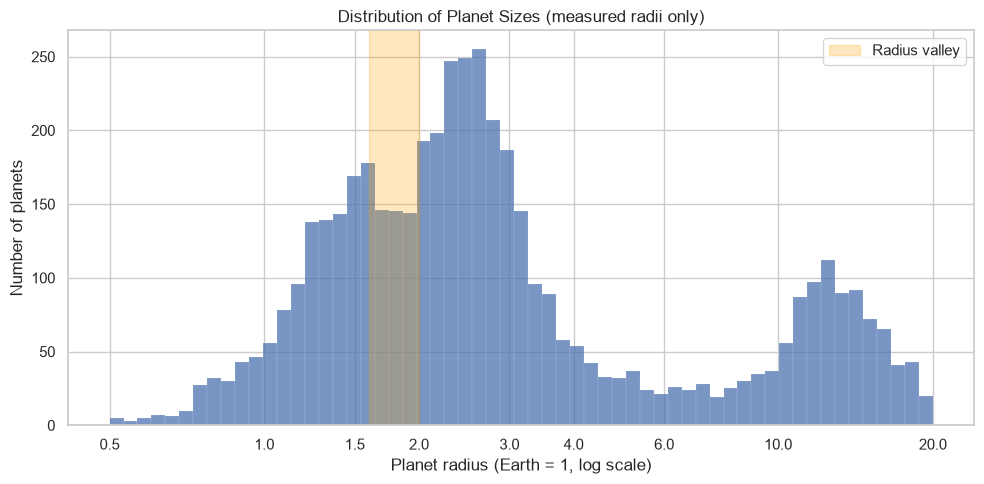

In [35]:
measured = df_clean[df_clean["radius_measured"]]
bins = np.logspace(np.log10(0.5), np.log10(20), 60)

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(measured["radius_earth"], bins=bins, ax=ax, color="#4C72B0")
ax.set_xscale("log")
ax.axvspan(1.6, 2.0, color="orange", alpha=0.25, label="Radius valley")
ax.set_xticks([0.5, 1, 1.5, 2, 3, 4, 6, 10, 20])
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.set_title("Distribution of Planet Sizes (measured radii only)")
ax.set_xlabel("Planet radius (Earth = 1, log scale)")
ax.set_ylabel("Number of planets")
ax.legend()
plt.tight_layout()
plt.savefig("../report/figures/01_radius_histogram.png", dpi=150)
plt.show()

**Insight:** Planet sizes are not evenly spread. There are two peaks among small planets,
around 1.3 and 2.5 Earth radii, separated by a dip at about 1.6–2.0 Earth radii, known as the
**radius valley** (Fulton et al., 2017). Planets rarely end up this size, likely because many lose
their atmospheres to radiation from their star.
Only measured radii were used: including calculated radii created an artificial spike around 12–13 Earth radii.

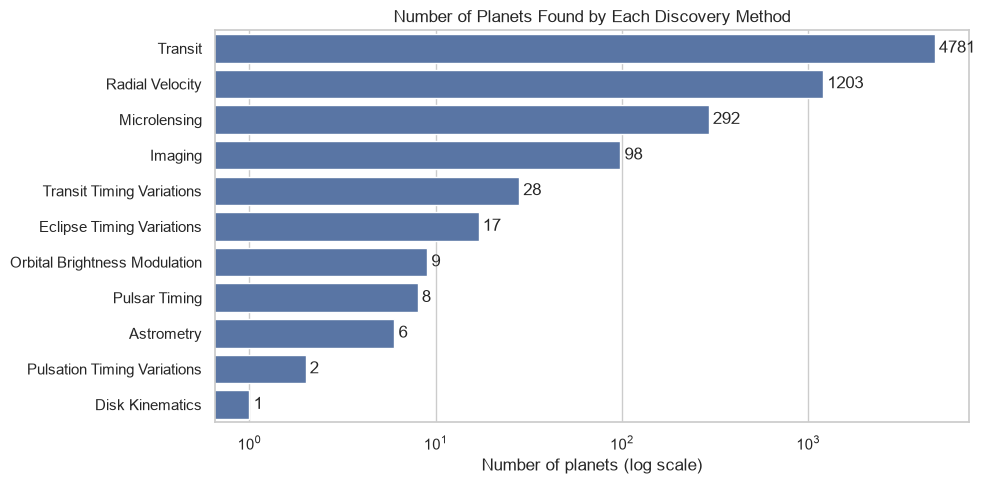

In [36]:
fig, ax = plt.subplots(figsize=(10, 5))
order = df_clean["discovery_method"].value_counts().index
sns.countplot(data=df_clean, y="discovery_method", order=order, ax=ax, color="#4C72B0")
ax.bar_label(ax.containers[0], padding=3)
ax.set_xscale("log")
ax.set_title("Number of Planets Found by Each Discovery Method")
ax.set_xlabel("Number of planets (log scale)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../report/figures/02_discovery_methods.png", dpi=150)
plt.show()

**Insight:** Transit found 4,781 planets (74%) and Radial Velocity 1,203 (19%).
The other 9 methods together found less than 7%. Our picture of exoplanets is therefore
shaped mostly by what the Transit method is able to detect.

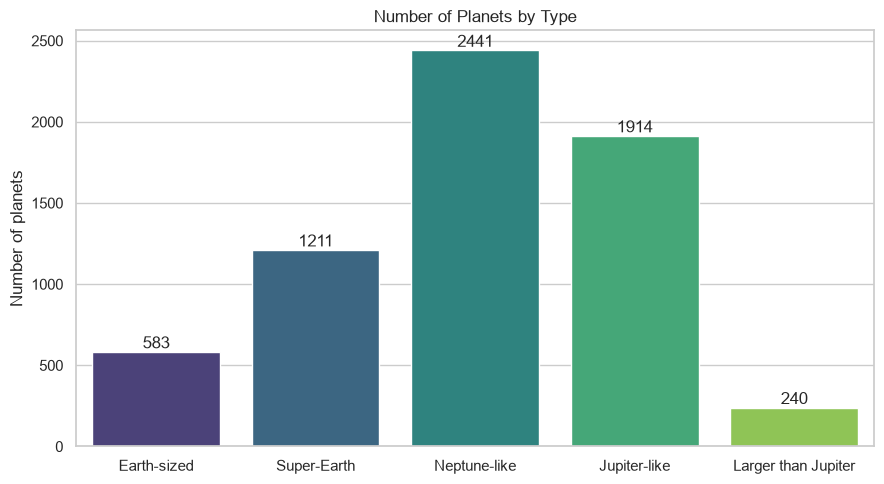

In [39]:
type_order = ["Earth-sized", "Super-Earth", "Neptune-like", "Jupiter-like", "Larger than Jupiter"]

fig, ax = plt.subplots(figsize=(9, 5))
sns.countplot(data=df_clean, x="planet_type", order=type_order, ax=ax,
              palette="viridis", hue="planet_type", legend=False, dodge=False)
for container in ax.containers:
    ax.bar_label(container)
ax.set_title("Number of Planets by Type")
ax.set_xlabel("")
ax.set_ylabel("Number of planets")
plt.tight_layout()
plt.savefig("../report/figures/03_planet_types.png", dpi=150)
plt.show()

**Insight:** Neptune-like planets are the most common type (2,441), while Earth-sized planets are only 583 (~9%).
Planets between Earth and Neptune in size, which do not exist in our Solar System, make up the majority.
Note that Earth-sized planets are harder to detect, so they are likely under-counted.

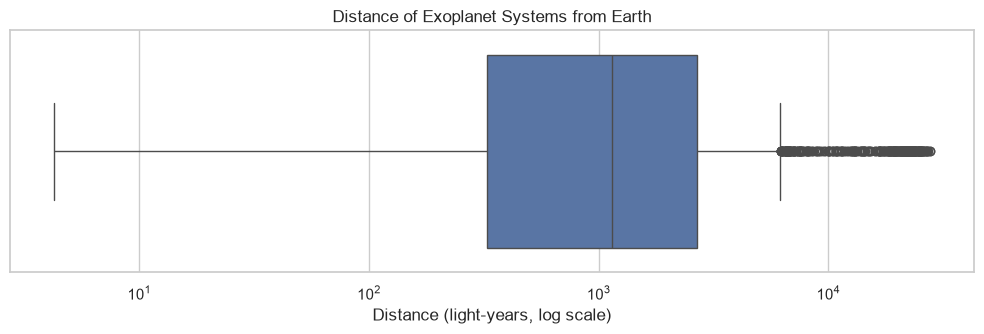

count     6394.000000
mean      2305.567282
std       4019.671788
min          4.240000
25%        325.442500
50%       1142.860000
75%       2667.670000
max      27723.260000
Name: distance_ly, dtype: float64

In [38]:
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.boxplot(x=df_clean["distance_ly"], ax=ax, color="#4C72B0")
ax.set_xscale("log")
ax.set_title("Distance of Exoplanet Systems from Earth")
ax.set_xlabel("Distance (light-years, log scale)")
plt.tight_layout()
plt.savefig("../report/figures/04_distance_boxplot.png", dpi=150)
plt.show()

df_clean["distance_ly"].describe()

**Insight:** Half of all known exoplanets are more than ~1,100 light-years away.
Only 537 planets lie within 100 light-years. The farthest planets (thousands of light-years away)
appear as outliers and were mostly found by Microlensing, a method that works at great distances.

### 5.2 Bivariate & multivariate analysis

Planets with reliable mass and radius: 1557


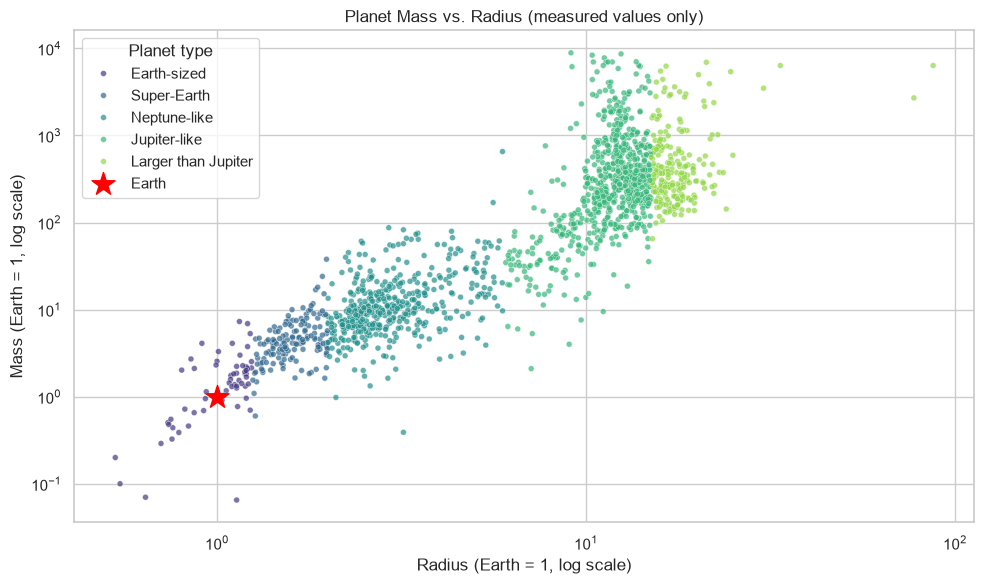

In [40]:
reliable = df_clean[
    (df_clean["mass_quality"] == "Measured")
    & df_clean["radius_measured"]
    & ~df_clean["suspicious_density"]
]
print("Planets with reliable mass and radius:", len(reliable))

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=reliable, x="radius_earth", y="mass_earth", hue="planet_type",
                hue_order=type_order, palette="viridis", s=18, alpha=0.7, ax=ax)
ax.scatter(1, 1, marker="*", s=300, color="red", zorder=5, label="Earth")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Planet Mass vs. Radius (measured values only)")
ax.set_xlabel("Radius (Earth = 1, log scale)")
ax.set_ylabel("Mass (Earth = 1, log scale)")
ax.legend(title="Planet type")
plt.tight_layout()
plt.savefig("../report/figures/05_mass_vs_radius.png", dpi=150)
plt.show()

**Insight:** Mass and radius rise together (Spearman correlation = 0.85), but the relationship bends:
above ~10 Earth radii, planets become much heavier without getting bigger, because gas giants compress
under their own gravity. Only 1,557 planets have both a reliably measured mass and radius,
which shows how rare complete measurements still are.

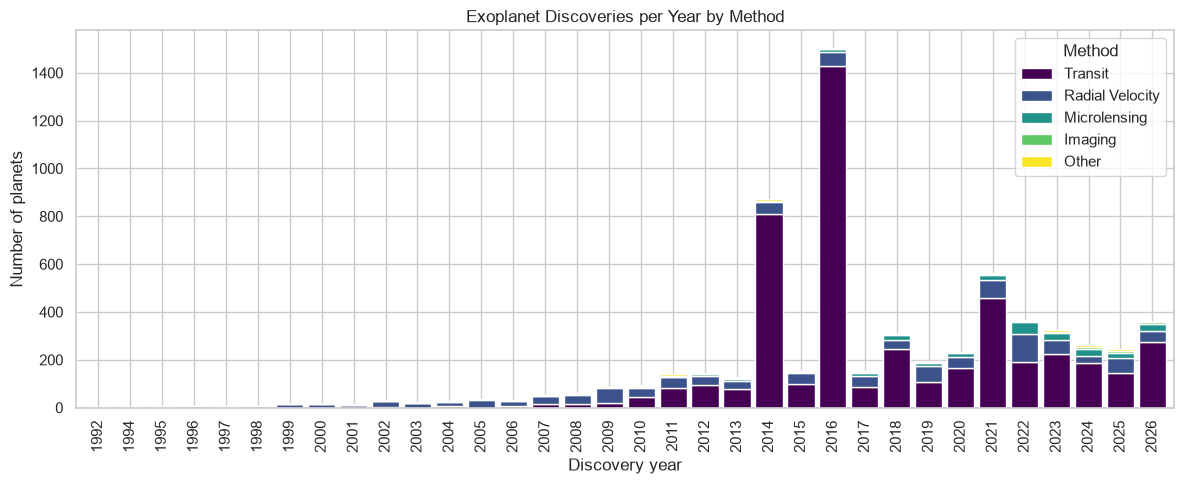

In [41]:
top_methods = ["Transit", "Radial Velocity", "Microlensing", "Imaging"]
method_grouped = df_clean["discovery_method"].astype(str).where(
    df_clean["discovery_method"].isin(top_methods), "Other"
)
per_year = pd.crosstab(df_clean["discovery_year"], method_grouped)[top_methods + ["Other"]]

fig, ax = plt.subplots(figsize=(12, 5))
per_year.plot(kind="bar", stacked=True, ax=ax, width=0.85, colormap="viridis")
ax.set_title("Exoplanet Discoveries per Year by Method")
ax.set_xlabel("Discovery year")
ax.set_ylabel("Number of planets")
ax.legend(title="Method")
plt.tight_layout()
plt.savefig("../report/figures/06_discoveries_per_year.png", dpi=150)
plt.show()

**Insight:** Before 2010, most planets were found by Radial Velocity. The two huge spikes in 2014 and 2016
are NASA's Kepler space telescope, which confirmed hundreds of planets at once (1,502 planets in 2016 alone).
Since 2018, the TESS telescope continued finding planets at a steady pace.
The dataset's dominance by Transit is a direct result of these missions.

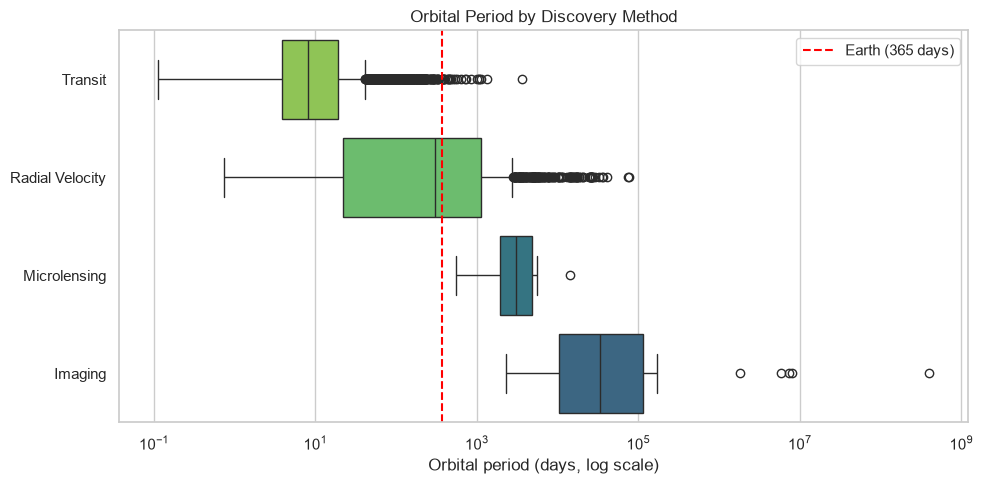

discovery_method
Imaging            33100.000000
Microlensing        3042.500000
Radial Velocity      305.500000
Transit                7.974198
Name: orbital_period_days, dtype: float64

In [45]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df_clean[df_clean["discovery_method"].isin(top_methods)],
            x="orbital_period_days", y="discovery_method", order=top_methods,
            hue="discovery_method", palette="viridis", legend=False, dodge=False, ax=ax)
ax.set_xscale("log")
ax.axvline(365, color="red", linestyle="--", label="Earth (365 days)")
ax.set_title("Orbital Period by Discovery Method")
ax.set_xlabel("Orbital period (days, log scale)")
ax.set_ylabel("")
ax.legend()
plt.tight_layout()
plt.savefig("../report/figures/07_period_by_method.png", dpi=150)
plt.show()

df_clean[df_clean["discovery_method"].isin(top_methods)].groupby("discovery_method", observed=True)["orbital_period_days"].median()

**Insight:** Each method finds a different kind of planet. Transit planets have a median "year" of only
8 days, because planets close to their star pass in front of it more often and are easier to catch.
Imaging finds planets with orbits of tens of thousands of days, because they are far enough from
their star to be photographed. **This is detection bias**: the typical exoplanet in the dataset
reflects our tools, not necessarily what is most common in the galaxy.

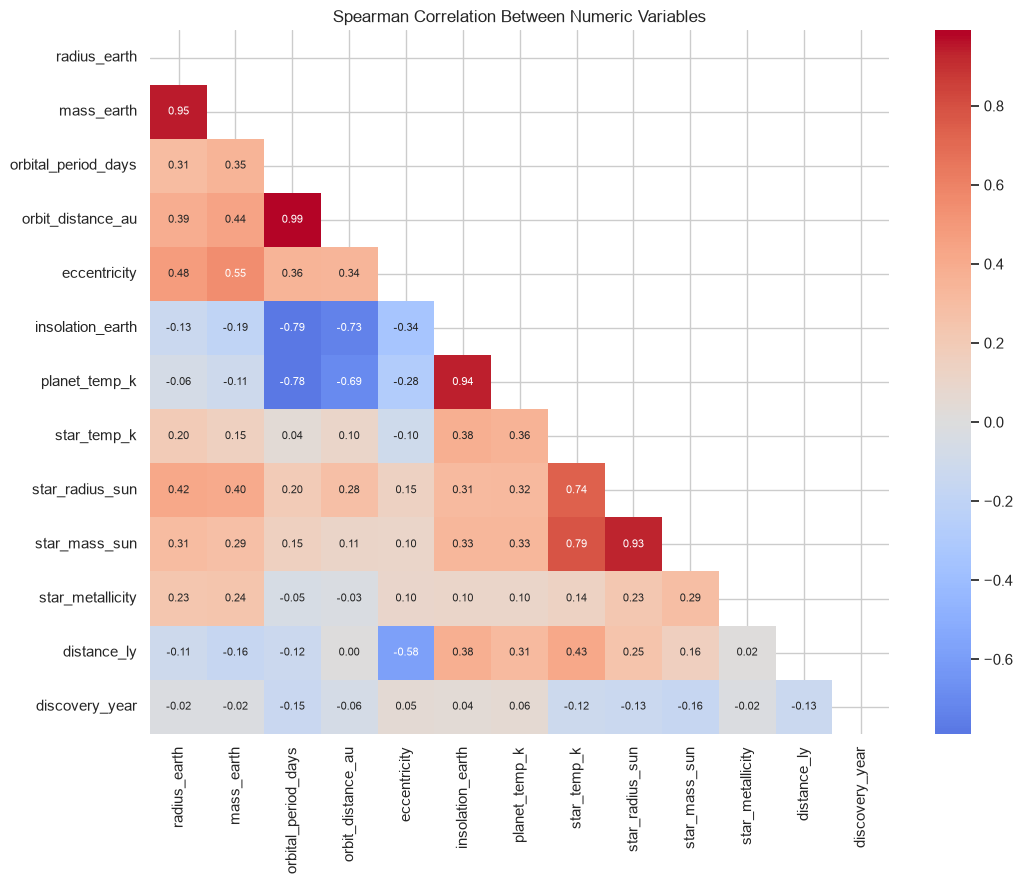

In [43]:
heat_cols = ["radius_earth", "mass_earth", "orbital_period_days", "orbit_distance_au",
             "eccentricity", "insolation_earth", "planet_temp_k", "star_temp_k",
             "star_radius_sun", "star_mass_sun", "star_metallicity", "distance_ly", "discovery_year"]
corr = df_clean[heat_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            annot_kws={"size": 8}, ax=ax)
ax.set_title("Spearman Correlation Between Numeric Variables")
plt.tight_layout()
plt.savefig("../report/figures/08_correlation_heatmap.png", dpi=150)
plt.show()

**Insight:**
- **Orbital period ↔ orbit distance (0.99):** planets farther from their star take longer to orbit it (Kepler's third law).
- **Insolation ↔ planet temperature (0.94):** planets receiving more energy are hotter.
- **Orbital period ↔ insolation (−0.79):** planets close to their star (short years) receive much more energy.
- **Star mass ↔ star radius (0.93):** bigger stars are heavier.
- **Radius ↔ mass shows 0.95 here, but only 0.85 using measured values.** The difference comes from the
  ~3,000 masses that were calculated from radius, which artificially strengthen the correlation.
  This confirms why flagging estimated masses in the cleaning step was necessary.

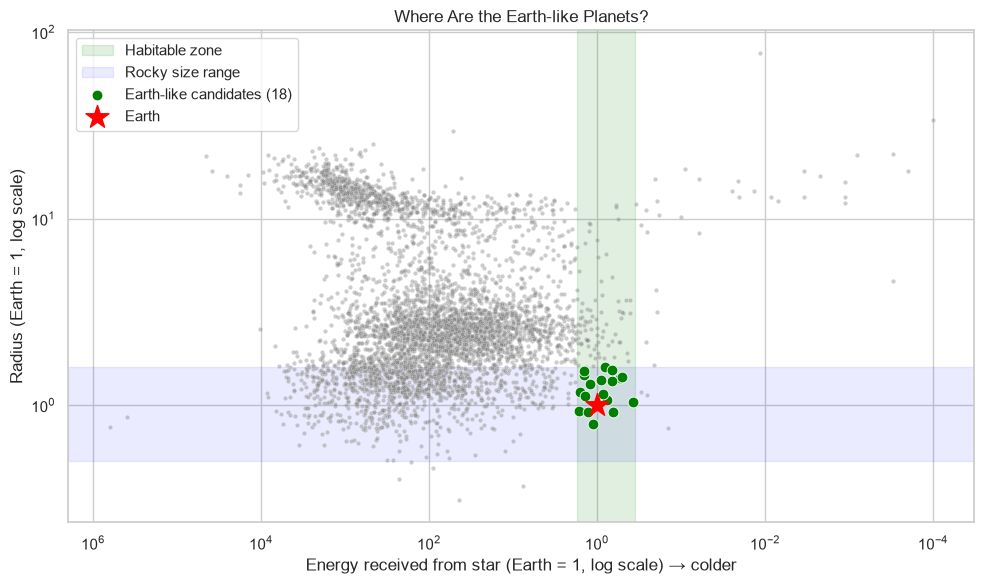

,planet_name,radius_earth,insolation_earth,distance_ly
377,Gliese 12 b,0.930,1.620,39.82
6146,TRAPPIST-1 d,0.788,1.115,40.54
6147,TRAPPIST-1 e,0.920,0.646,40.54
6148,TRAPPIST-1 f,1.045,0.373,40.54
6060,TOI-700 d,1.145,0.850,101.52


In [44]:
measured = df_clean[df_clean["radius_measured"]]
candidates = measured[measured["earth_like"]]

fig, ax = plt.subplots(figsize=(10, 6))
ax.axvspan(0.35, 1.75, color="green", alpha=0.12, label="Habitable zone")
ax.axhspan(0.5, 1.6, color="blue", alpha=0.08, label="Rocky size range")
sns.scatterplot(data=measured, x="insolation_earth", y="radius_earth",
                s=10, alpha=0.4, color="grey", ax=ax)
sns.scatterplot(data=candidates, x="insolation_earth", y="radius_earth",
                s=60, color="green", label=f"Earth-like candidates ({len(candidates)})", ax=ax)
ax.scatter(1, 1, marker="*", s=300, color="red", zorder=5, label="Earth")
ax.set_xscale("log")
ax.set_yscale("log")
ax.invert_xaxis()
ax.set_title("Where Are the Earth-like Planets?")
ax.set_xlabel("Energy received from star (Earth = 1, log scale) → colder")
ax.set_ylabel("Radius (Earth = 1, log scale)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("../report/figures/09_earth_like_planets.png", dpi=150)
plt.show()

candidates.nsmallest(5, "distance_ly")[["planet_name", "radius_earth", "insolation_earth", "distance_ly"]]

**Insight:** Out of 4,851 planets with a measured radius, only **18** are both rocky-sized and receive
an Earth-like amount of energy. The nearest are Gliese 12 b (39.8 light-years) and the TRAPPIST-1 system
(40.5 light-years), which has three candidates. Proxima Centauri b is closer (4.2 light-years),
but its radius was never measured, so it is not included here.
**Answer to the research question:** potentially Earth-like planets exist, but they are rare,
and the nearest confirmed-size candidates are about 40 light-years away.

## Step 6: Insights Summary

### Patterns discovered
- **Neptune-like planets dominate** (2,441 planets), and Earth-sized planets are only ~9% of the total.
  The most common planets are between Earth and Neptune in size, a type that does not exist in our Solar System.
- **The radius valley:** small planets cluster at ~1.3 and ~2.5 Earth radii, with a clear gap at ~1.6–2.0,
  matching a known scientific discovery (Fulton et al., 2017).
- **Discoveries come in waves:** NASA's Kepler mission produced huge spikes in 2014 and 2016
  (1,502 planets in 2016 alone), and TESS has continued since 2018.

### Interesting relationships
- **Detection bias:** each method finds a different kind of planet. Transit planets have a median orbit
  of 8 days, while Imaging planets have a median orbit of 33,100 days. Since Transit found 74% of all planets,
  the dataset favors planets very close to their stars.
- **Orbit and temperature:** planets with short orbits receive far more energy and are much hotter
  (Spearman: −0.79 between orbital period and insolation; 0.94 between insolation and temperature).
- **Mass and radius** rise together (0.85 using measured values), with a bend above ~10 Earth radii
  where gas giants get heavier without getting bigger.

### Outliers
- Many extreme values are real: COCONUTS-2 b (orbit of 402 million days), NN Ser (a 57,000 K star),
  KOI-55 b (7,778 K).
- Some were not: Kepler-80 f's mass of 12,651 Earth masses was an **upper limit**, not a measurement.
  239 such masses were found and removed, and 25 planets with impossible densities were flagged.

### Key takeaways
1. **Data quality matters:** ~47% of masses and ~24% of radii were calculated, not measured.
   Including them inflated the mass–radius correlation from 0.85 to 0.95.
2. **Our tools shape what we see:** the "typical" exoplanet in the data reflects what is easiest to detect.
3. **Answer to the main question:** only **18 planets** with a measured size are rocky-sized and receive
   an Earth-like amount of energy. The nearest are Gliese 12 b and TRAPPIST-1 d, e and f, about 40 light-years away.
   Proxima Centauri b is closer (4.2 light-years), but its size has never been measured.